# 1. Problem Definition


For this project we will investigate the Boston House Price dataset. Each record in the database describes a Boston suburb or town. The data was drawn from the Boston Standard Metropolitan Statistical Area (SMSA) in 1970. The attributes are defined as follows (taken from the UCI Machine Learning Repository1):
1. **CRIM**: per capita crime rate by town
2. **ZN**: proportion of residential land zoned for lots over 25,000 sq.ft.
3. **INDUS**: proportion of non-retail business acres per town
4. **CHAS**: Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
5. **NOX**: nitric oxides concentration (parts per 10 million)
6. **RM**: average number of rooms per dwelling
7. **AGE**: proportion of owner-occupied units built prior to 1940
8. **DIS**: weighted distances to five Boston employment centers
9. **RAD**: index of accessibility to radial highways
10. **TAX**: full-value property-tax rate per \$10,000
11. **PTRATIO**: pupil-teacher ratio by town
12. **B**: 1000(Bk − 0.63)2 where Bk is the proportion of blacks by town
13. **LSTAT**: % lower status of the population
14. **MEDV**: Median value of owner-occupied homes in $1000s
We can see that the input attributes have a mixture of units.

In [67]:
from google.colab import drive #accessing the google drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [68]:
%cd /content/gdrive/MyDrive/ColabNotebooks/ICT110-AppDev/ColabNotes

/content/gdrive/MyDrive/ColabNotebooks/ICT110-AppDev/ColabNotes


## a. Load the neeeded packages


In [172]:
# Load libraries

from numpy import arange
from matplotlib import pyplot
from pandas import read_csv
from pandas import set_option
from pathlib import Path
from datetime import datetime

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from pandas.plotting import scatter_matrix
from sklearn.preprocessing import StandardScaler,FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys, json, warnings
import sklearn, joblib

warnings.filterwarnings("ignore")
SEED = 7
np.random.seed(SEED)


print('Done')

Done


In [102]:
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | statsmodels {sm.__version__}")

python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | statsmodels 0.15.0


## b. Load the dataset

In [85]:
#From sklearn tutorial.
from sklearn.datasets import load_boston

boston = load_boston()

print( "Type of boston dataset:", type(boston))

ImportError: 
`load_boston` has been removed from scikit-learn since version 1.2.

The Boston housing prices dataset has an ethical problem: as
investigated in [1], the authors of this dataset engineered a
non-invertible variable "B" assuming that racial self-segregation had a
positive impact on house prices [2]. Furthermore the goal of the
research that led to the creation of this dataset was to study the
impact of air quality but it did not give adequate demonstration of the
validity of this assumption.

The scikit-learn maintainers therefore strongly discourage the use of
this dataset unless the purpose of the code is to study and educate
about ethical issues in data science and machine learning.

In this special case, you can fetch the dataset from the original
source::

    import pandas as pd
    import numpy as np

    data_url = "http://lib.stat.cmu.edu/datasets/boston"
    raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
    data = np.hstack([raw_df.values[:

In [86]:
#Boston Housing
data_url = "http://lib.stat.cmu.edu/datasets/boston"

raw_df = pd.read_csv(
    data_url,
    sep=r"\s+",
    skiprows=22,
    header=None
)

# Combine every two rows into one observation
data = np.hstack([
    raw_df.values[::2, :],
    raw_df.values[1::2, :2]
])

# Extract the target variable (median house value)
target = raw_df.values[1::2, 2]

In [ ]:
# Define column names
columns = [
    'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE',
    'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT'
]

In [ ]:
# Create the DataFrame
df_Boston = pd.DataFrame(data, columns=columns)

# Add the target variable
df_Boston['MEDV'] = target

In [ ]:
# Display the first five rows
display(df_Boston.head())

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [ ]:
df_Boston.to_csv('Datasets/Boston-housing.csv', index=False)

You can see that we are specifying the short names for each attribute so that we can reference them clearly later. You can also see that attributes are delimited by whitespace rather than commas in this file and we indicate this to read csv() function via the delim whitespace argument. We now have our data loaded.


Looks like they are all continuous (Independent Variable)IV and continuous (Dependent Variable)DV.
- CRIM per capita crime rate by town
- ZN proportion of residential land zoned for lots over 25,000 sq.ft.
- INDUS proportion of non-retail business acres per town
- CHAS Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
- NOX nitric oxides concentration (parts per 10 million)
- RM average number of rooms per dwelling
- AGE proportion of owner-occupied units built prior to 1940
- DIS weighted distances to five Boston employment centres
- RAD index of accessibility to radial highways
- TAX full-value property-tax rate per 10,000
- PTRATIO pupil-teacher ratio by town
- B 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town - LSTAT % lower status of the population
- MEDV Median value of owner-occupied homes in 1000’s Let’s check for missing values.

# 2. Summarize and Analyze the data

## a. Descriptive Statistics

In [ ]:
# dimensions of the dataset
print(df_Boston.shape)

(506, 14)


We have 506 instances to work with and can confirm the data has 14 attributes including
the output attribute MEDV.

In [ ]:
# types
print(df_Boston.dtypes)

CRIM       float64
ZN         float64
INDUS      float64
CHAS       float64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD        float64
TAX        float64
PTRATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object


We can see that all of the attributes are numeric, mostly real values (float) and some have been interpreted as integers (int).

In [70]:
#check for missing values
print(df_Boston.isnull().sum())

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


In [ ]:
# peek at the data
print(df_Boston.head(20))

       CRIM    ZN  INDUS  CHAS    NOX     RM    AGE     DIS  RAD    TAX  \
0   0.00632  18.0   2.31   0.0  0.538  6.575   65.2  4.0900  1.0  296.0   
1   0.02731   0.0   7.07   0.0  0.469  6.421   78.9  4.9671  2.0  242.0   
2   0.02729   0.0   7.07   0.0  0.469  7.185   61.1  4.9671  2.0  242.0   
3   0.03237   0.0   2.18   0.0  0.458  6.998   45.8  6.0622  3.0  222.0   
4   0.06905   0.0   2.18   0.0  0.458  7.147   54.2  6.0622  3.0  222.0   
5   0.02985   0.0   2.18   0.0  0.458  6.430   58.7  6.0622  3.0  222.0   
6   0.08829  12.5   7.87   0.0  0.524  6.012   66.6  5.5605  5.0  311.0   
7   0.14455  12.5   7.87   0.0  0.524  6.172   96.1  5.9505  5.0  311.0   
8   0.21124  12.5   7.87   0.0  0.524  5.631  100.0  6.0821  5.0  311.0   
9   0.17004  12.5   7.87   0.0  0.524  6.004   85.9  6.5921  5.0  311.0   
10  0.22489  12.5   7.87   0.0  0.524  6.377   94.3  6.3467  5.0  311.0   
11  0.11747  12.5   7.87   0.0  0.524  6.009   82.9  6.2267  5.0  311.0   
12  0.09378  12.5   7.87 

In [ ]:
# descriptions
print(df_Boston.describe())

             CRIM          ZN       INDUS        CHAS         NOX          RM  \
count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
mean     3.613524   11.363636   11.136779    0.069170    0.554695    6.284634   
std      8.601545   23.322453    6.860353    0.253994    0.115878    0.702617   
min      0.006320    0.000000    0.460000    0.000000    0.385000    3.561000   
25%      0.082045    0.000000    5.190000    0.000000    0.449000    5.885500   
50%      0.256510    0.000000    9.690000    0.000000    0.538000    6.208500   
75%      3.677083   12.500000   18.100000    0.000000    0.624000    6.623500   
max     88.976200  100.000000   27.740000    1.000000    0.871000    8.780000   

              AGE         DIS         RAD         TAX     PTRATIO           B  \
count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
mean    68.574901    3.795043    9.549407  408.237154   18.455534  356.674032   
std     28.148861    2.1057

In [ ]:
# correlation
print(df_Boston.corr(method='pearson'))

             CRIM        ZN     INDUS      CHAS       NOX        RM       AGE  \
CRIM     1.000000 -0.200469  0.406583 -0.055892  0.420972 -0.219247  0.352734   
ZN      -0.200469  1.000000 -0.533828 -0.042697 -0.516604  0.311991 -0.569537   
INDUS    0.406583 -0.533828  1.000000  0.062938  0.763651 -0.391676  0.644779   
CHAS    -0.055892 -0.042697  0.062938  1.000000  0.091203  0.091251  0.086518   
NOX      0.420972 -0.516604  0.763651  0.091203  1.000000 -0.302188  0.731470   
RM      -0.219247  0.311991 -0.391676  0.091251 -0.302188  1.000000 -0.240265   
AGE      0.352734 -0.569537  0.644779  0.086518  0.731470 -0.240265  1.000000   
DIS     -0.379670  0.664408 -0.708027 -0.099176 -0.769230  0.205246 -0.747881   
RAD      0.625505 -0.311948  0.595129 -0.007368  0.611441 -0.209847  0.456022   
TAX      0.582764 -0.314563  0.720760 -0.035587  0.668023 -0.292048  0.506456   
PTRATIO  0.289946 -0.391679  0.383248 -0.121515  0.188933 -0.355501  0.261515   
B       -0.385064  0.175520 

In [110]:
summary = pd.DataFrame({
    "skew": df_Boston.skew(),
    "excess_kurtosis": df_Boston.kurtosis(),
    "corr_with_MEDV": df_Boston.corr()["MEDV"],
}).round(3)
display(summary.sort_values("corr_with_MEDV"))
print("CHAS value counts:\n", df_Boston["CHAS"].value_counts().to_string())

,skew,excess_kurtosis,corr_with_MEDV
LSTAT,0.906,0.493,-0.738
PTRATIO,-0.802,-0.285,-0.508
INDUS,0.295,-1.234,-0.484
TAX,0.670,-1.142,-0.469
NOX,0.729,-0.065,-0.427
CRIM,5.223,37.131,-0.388
RAD,1.005,-0.867,-0.382
AGE,-0.599,-0.968,-0.377
CHAS,3.406,9.638,0.175
DIS,1.012,0.488,0.250


CHAS value counts:
 CHAS
0.0    471
1.0     35


## b. Data visualizations

Let’s look at visualizations of individual attributes. It is often useful to look at your data using multiple different visualizations in order to spark ideas. Let’s look at histograms of each attribute to get a sense of the data distributions.

### i. Univariate data visualization

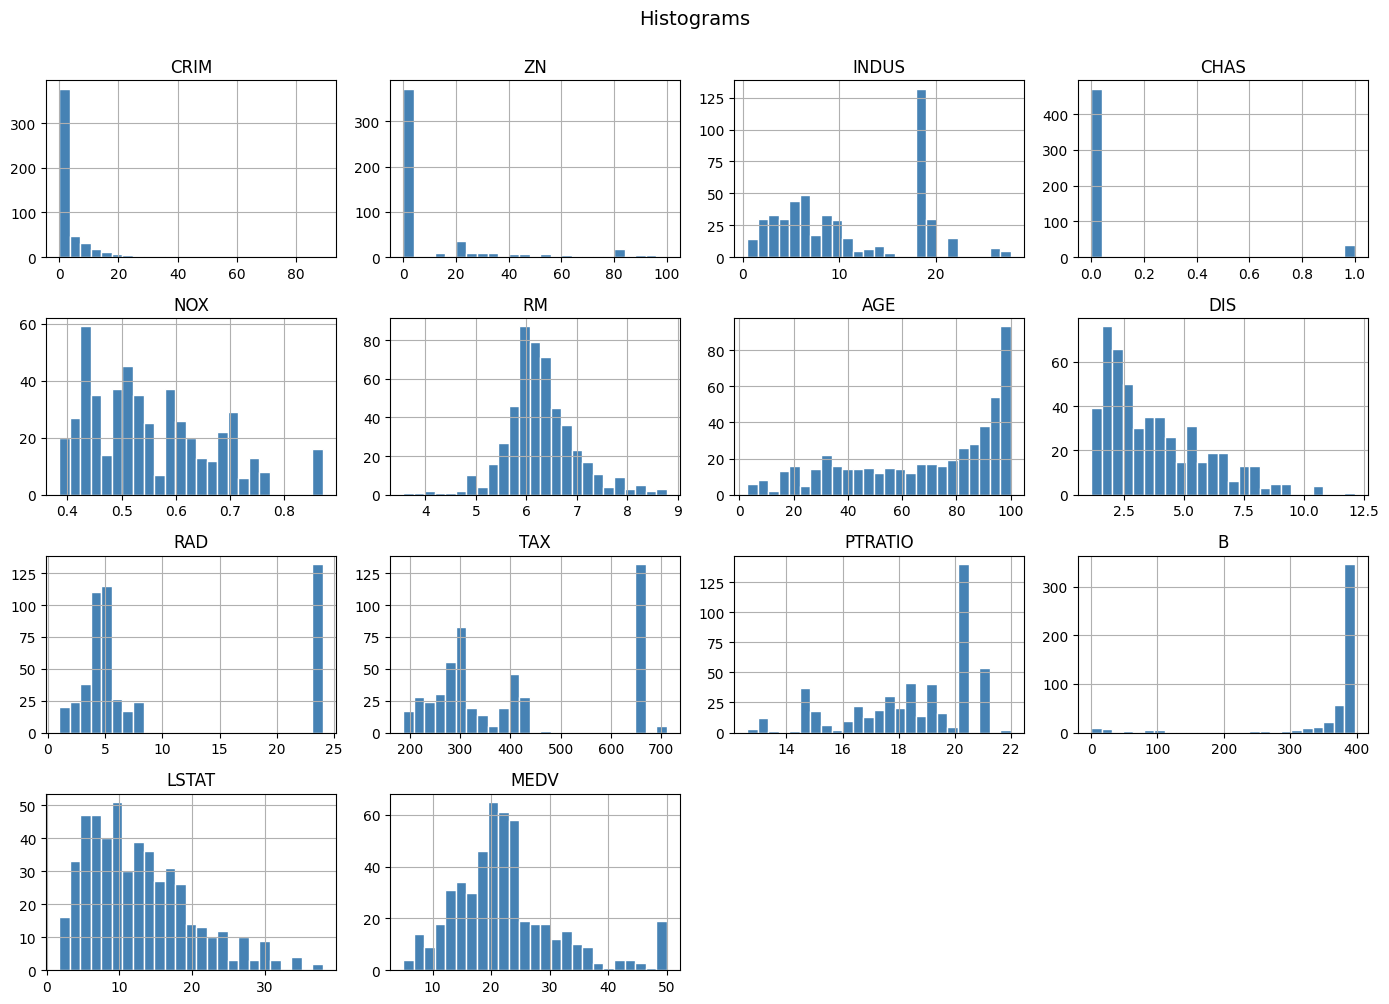

In [108]:
df_Boston.hist(bins=25, figsize=(14, 10), layout=(4, 4), color="steelblue", edgecolor="white")
plt.suptitle("Histograms", y=1.0, fontsize=14); plt.tight_layout()
pyplot.savefig('Datasets/01_Histogram',
               dpi = 300)

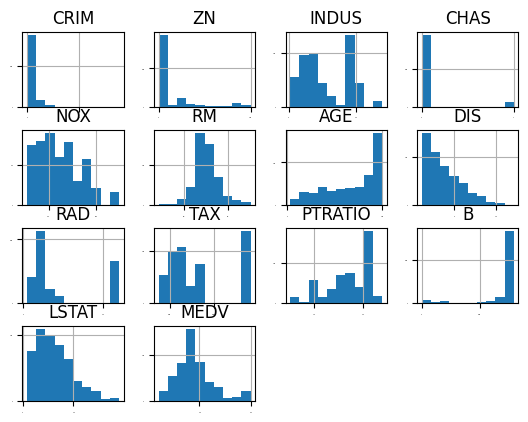

In [ ]:
# Unimodal data visualization
# histograms
df_Boston.hist(sharex=False, sharey=False, xlabelsize=1, ylabelsize=1)
pyplot.show()

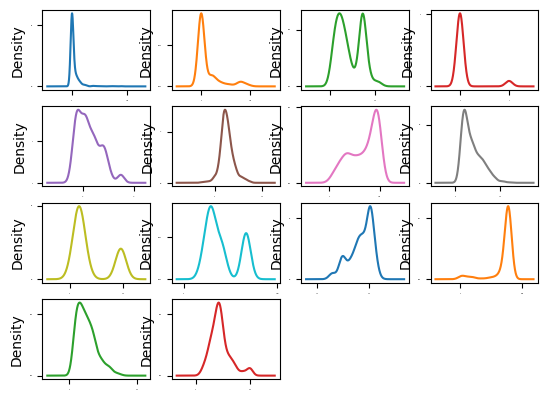

In [ ]:
# density
df_Boston.plot(kind='density', subplots=True, layout=(4,4), sharex=False, legend=False, fontsize=1)
pyplot.show()

This perhaps adds more evidence to our suspicion about possible exponential and bimodal distributions. It also looks like NOX, RM and LSTAT may be skewed Gaussian distributions, which might be helpful later with transforms.

Let’s look at the data with box and whisker plots of each attribute.

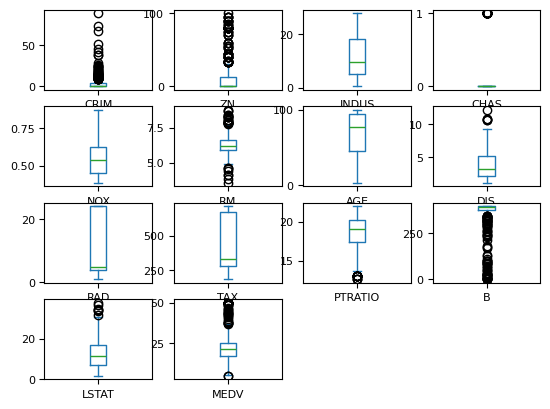

In [ ]:
# box and whisker plots
df_Boston.plot(kind='box', subplots=True, layout=(4,4), sharex=False, sharey=False, fontsize=8)
pyplot.show()

### ii. Multimodal data visualization

Let’s look at some visualizations of the interactions between variables. The best place to start is a scatter plot matrix.

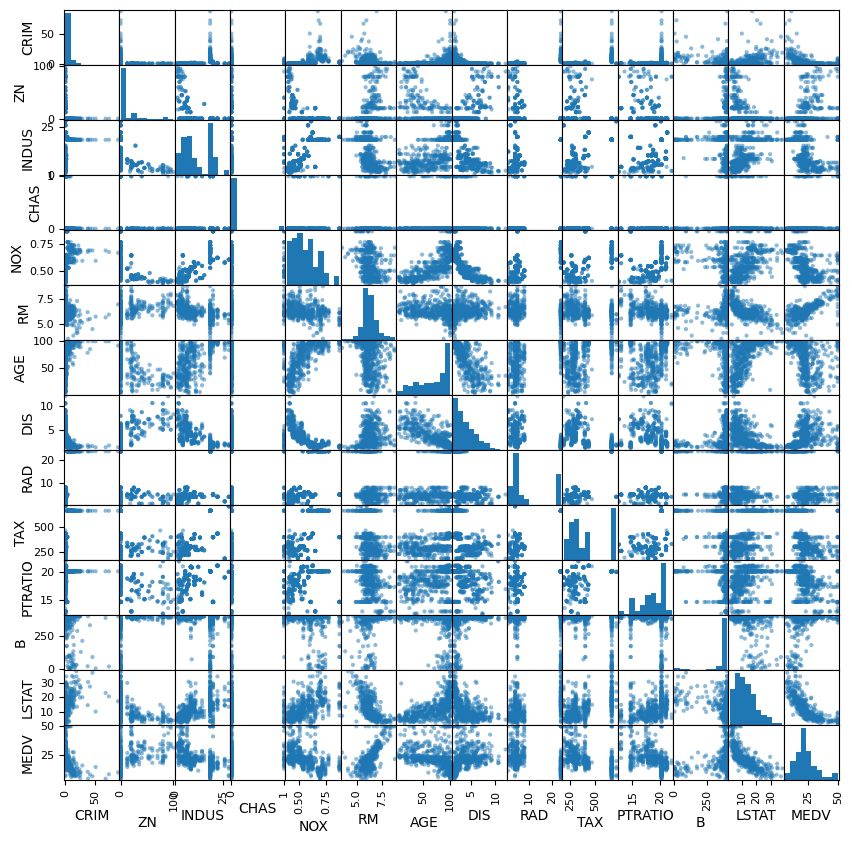

In [ ]:
# scatter plot matrix
from pandas.plotting import scatter_matrix

pyplot.rcParams["figure.figsize"] = [10, 10]

scatter_matrix(df_Boston)

pyplot.show()

Let’s also visualize the correlations between the attributes.

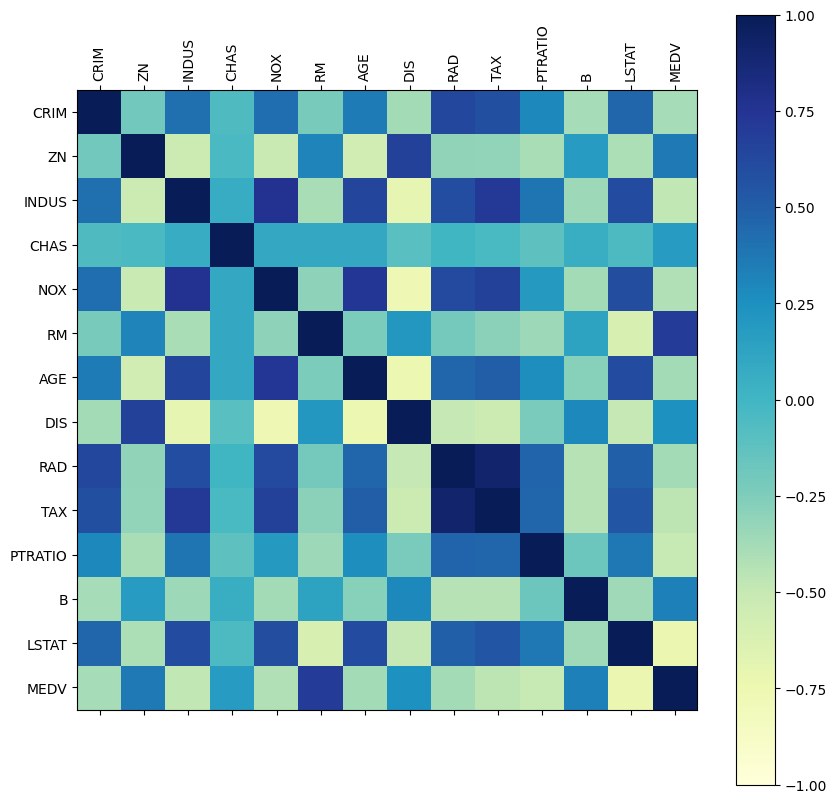

In [ ]:
# Get the column names from the DataFrame
names = df_Boston.columns.tolist()

# correlation matrix
fig = pyplot.figure()
ax = fig.add_subplot(111)
cax = ax.matshow(df_Boston.corr(),
                 vmin=-1, vmax=1,       # sets the correlation scale from −1 to +1.
                 interpolation='none',
                 cmap = 'YlGnBu')       # color
fig.colorbar(cax)                       # displays the color scale
ticks = numpy.arange(0,14,1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(names, rotation = 90)  # rotates the x-axis labels to improve readability
ax.set_yticklabels(names)
pyplot.show()

Interpreting the correlation matrix
- +1: Perfect positive correlation.
- 0: No linear correlation.
- −1: Perfect negative correlation.

**Correlation indicates association, not causation.**

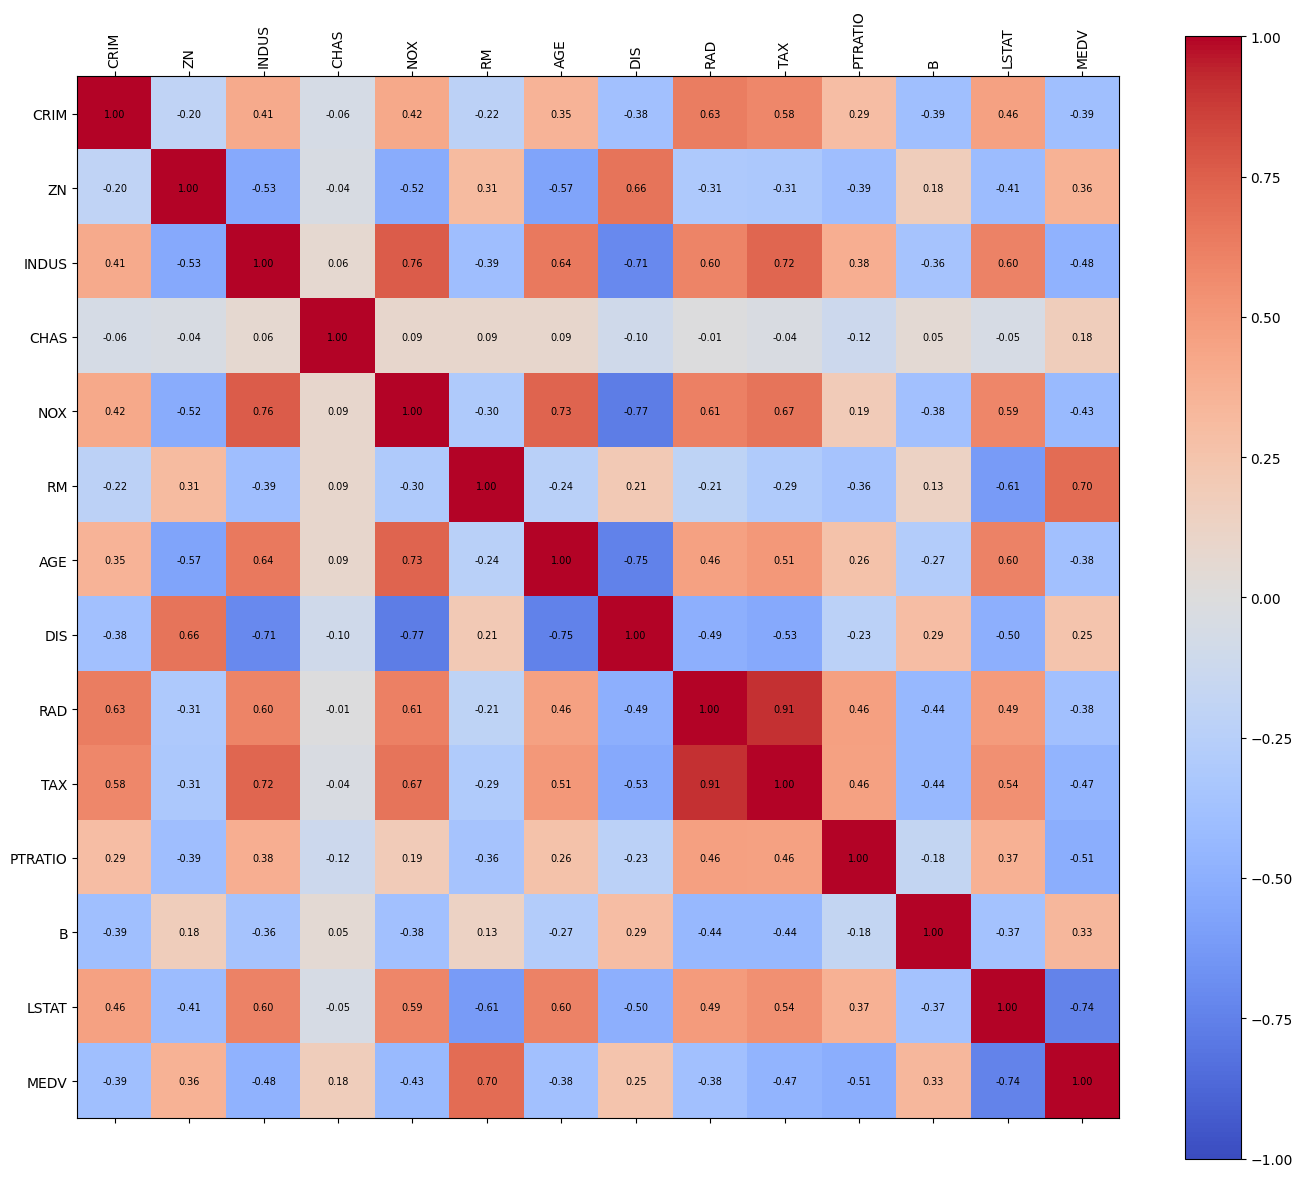

In [95]:
# Display correlation values in each cell

correlations = df_Boston.corr()
names = df_Boston.columns.tolist()

fig, ax = pyplot.subplots(figsize=(14, 12))

cax = ax.matshow(
    correlations,
    vmin=-1,
    vmax=1,
    interpolation='none',
    cmap='coolwarm'
)

fig.colorbar(cax)

ticks = numpy.arange(len(names))
ax.set_xticks(ticks)
ax.set_yticks(ticks)

ax.set_xticklabels(names, rotation=90)
ax.set_yticklabels(names)

# Display correlation values in each cell
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(
            j, i,
            f'{correlations.iloc[i, j]:.2f}',
            ha='center',
            va='center',
            color='black',
            fontsize=7
        )

pyplot.tight_layout()
# saving the figure
pyplot.savefig('Datasets/Boston-corr_model_plot.jpg',
               dpi = 300)
pyplot.show()

In [94]:
import os

print(os.path.exists('Datasets/Boston-corr_model_plot.jpg'))

True


As a general guide, an absolute correlation of **`0.70`** or higher may be considered strong

In [ ]:
features = df_Boston.drop(columns=['MEDV'])
corr_features = features.corr()

threshold = 0.70

for i in range(len(features.columns)):
    for j in range(i + 1, len(features.columns)):
        value = corr_features.iloc[i, j]

        if abs(value) >= threshold:
            print(
                f"{features.columns[i]} and "
                f"{features.columns[j]}: {value:.3f}"
            )

INDUS and NOX: 0.764
INDUS and DIS: -0.708
INDUS and TAX: 0.721
NOX and AGE: 0.731
NOX and DIS: -0.769
AGE and DIS: -0.748
RAD and TAX: 0.910


This identifies predictor pairs with absolute correlation of at least **`0.70`**, helping you investigate possible multicollinearity before fitting a linear regression model.

+ **`RAD and TAX: 0.910`** - Very strong positive correlation. Areas with greater accessibility to radial highways tend to have higher property tax rates.

Implications for Linear Regression
These relationships indicate potential multicollinearity among predictor variables. When predictors are strongly correlated, the regression model may have difficulty estimating their individual effects precisely. This can lead to unstable coefficients and larger standard errors.

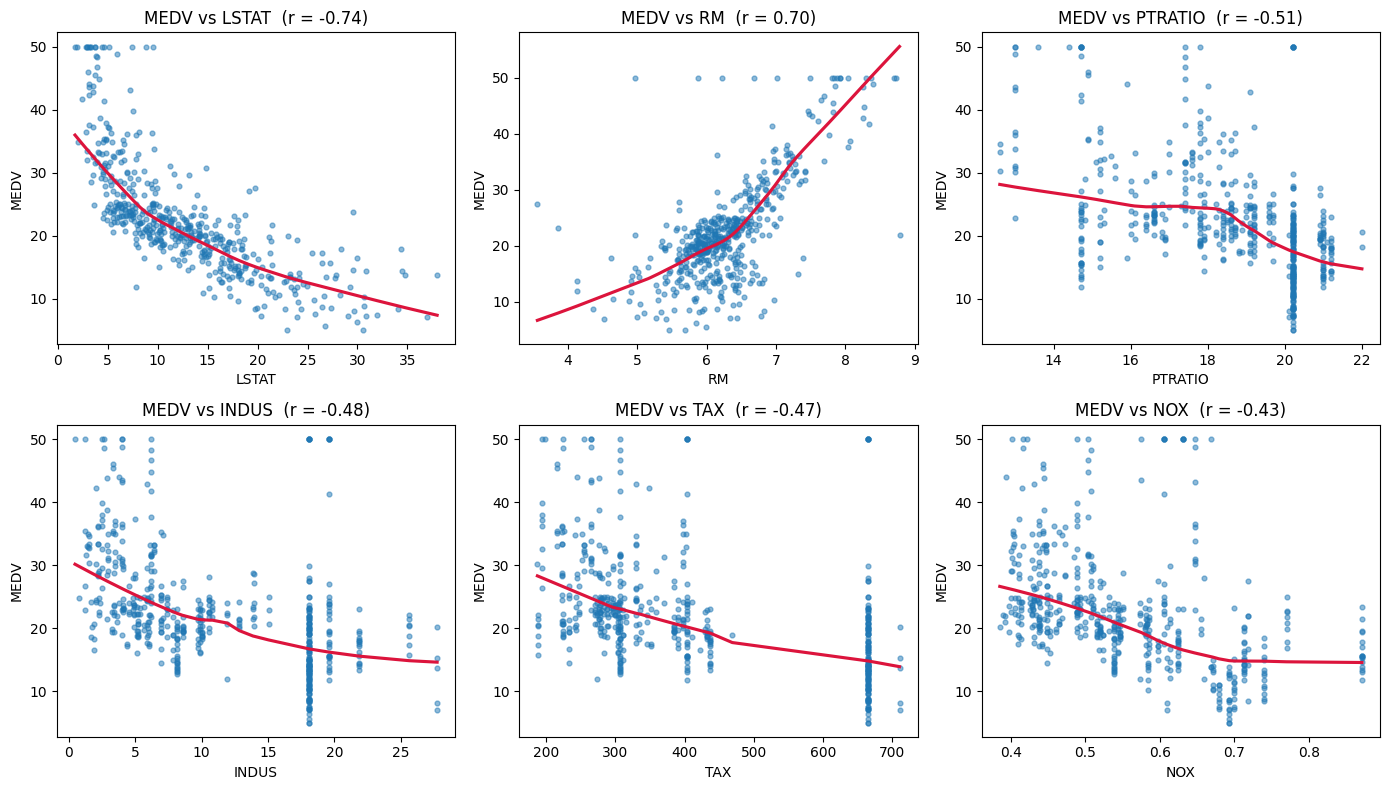

In [114]:
top = df_Boston.corr()["MEDV"].drop("MEDV").abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.ravel(), top):
    sns.regplot(data=df_Boston, x=c, y="MEDV", ax=ax, scatter_kws={"s": 12, "alpha": .5}, line_kws={"color": "crimson"}, lowess=True)
    ax.set_title(f"MEDV vs {c}  (r = {df_Boston[c].corr(df_Boston['MEDV']):.2f})")

# saving the figure
pyplot.savefig('Datasets/05_scatter_top_features.jpg',
               dpi = 300)
plt.tight_layout()


## Using OLS (Ordinary Least Square)

####  Linear Regression using `statsmodels` to examine the coefficients, their statistical significance, and potential multicollinearity implications.

Ordinary Least Squares (OLS) linear regression
1. Model Fit & Explanatory Power
    * $R^2$ (Coefficient of Determination): 0.741 (Adjusted $R^2$: 0.734). This indicates that approximately 74.1% of the variance in the median home value (MEDV) is explained by the 13 predictor features in this model.
    * F-statistic: 108.1 (p-value ~ 0), confirming that the overall model is highly statistically significant.
2. Individual Feature Significance (at $\alpha = 0.05$$\alpha = 0.05$)
    + Strongest Negative Impact:
        * NOX (Nitric oxides concentration): -17.77 (p < 0.001) — Higher pollution strongly relates to lower house prices.
        * DIS (Weighted distances to employment centers): -1.48 (p < 0.001).
        * LSTAT (% lower status of the population): -0.52 (p < 0.001).
        * PTRATIO (Pupil-teacher ratio): -0.95 (p < 0.001).
    + Strongest Positive Impact:
        * RM (Average number of rooms): +3.81 (p < 0.001) — Each additional room adds significantly to the expected median value.
        * CHAS (Charles River proximity): +2.69 (p = 0.002) — Homes bounding the river have a premium.
    + Non-Significant Features:
        * INDUS (p = 0.738) and AGE (p = 0.958) are not statistically significant predictors when all other variables are included in the model.
3. Diagnostic Warnings
    + Multicollinearity: The report notes a very high condition number ($1.51 \times 10^4$$1.51 \times 10^4$).
    + This aligns with our earlier discovery of highly correlated features (such as RAD and TAX at 0.91), indicating that the individual coefficient estimates could be unstable due to redundant information among the predictors.

In [ ]:
import statsmodels.api as sm

# Add a constant term to the predictor variables for the intercept
X_constant = sm.add_constant(features)

# Fit the ordinary least squares (OLS) model
model_ols = sm.OLS(target, X_constant).fit()

# Print the summary statistics of the model
print(model_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     108.1
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          6.72e-135
Time:                        12:26:06   Log-Likelihood:                -1498.8
No. Observations:                 506   AIC:                             3026.
Df Residuals:                     492   BIC:                             3085.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         36.4595      5.103      7.144      0.0

In [ ]:
### Collinearity and heteroscedasticity diagnostics

,VIF
TAX,9.01
RAD,7.48
NOX,4.39
INDUS,3.99
DIS,3.96
AGE,3.10
LSTAT,2.94
ZN,2.30
RM,1.93
PTRATIO,1.80


Breusch-Pagan LM p-value: 6.27e-09  (small => heteroscedastic residuals)


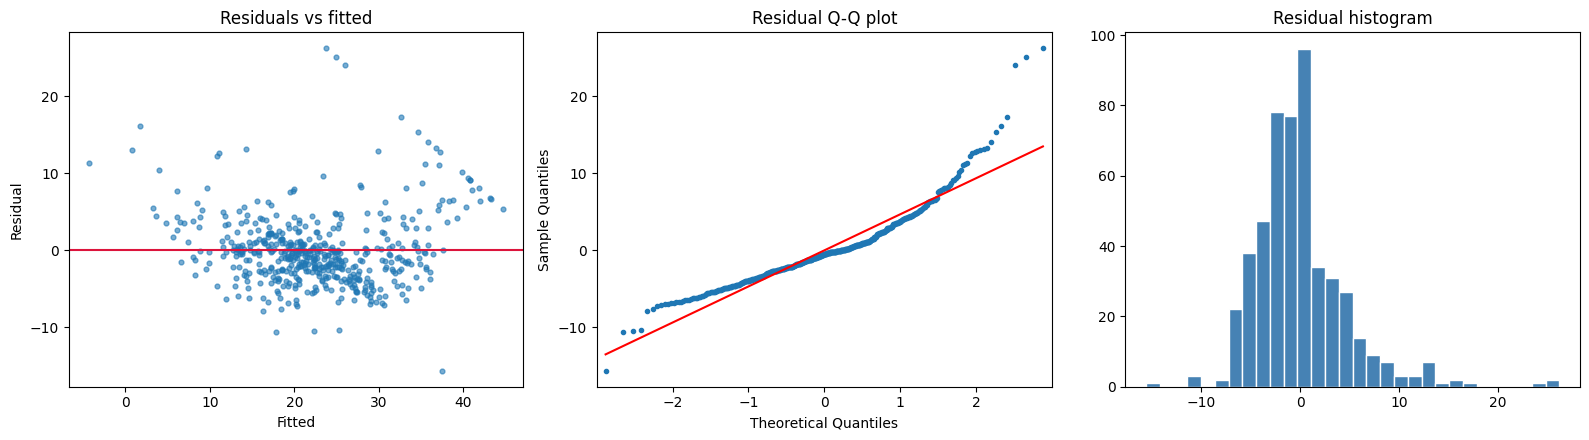

In [124]:
# Collinearity and heteroscedasticity diagnostics
vif = pd.Series([variance_inflation_factor(X_constant.values, i) for i in range(1, X_constant.shape[1])],
                index=X_constant.columns[1:], name="VIF").round(2).sort_values(ascending=False)
display(vif.to_frame())
bp = het_breuschpagan(model_ols.resid, X_constant)
print(f"Breusch-Pagan LM p-value: {bp[1]:.2e}  (small => heteroscedastic residuals)")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(model_ols.fittedvalues, model_ols.resid, s=12, alpha=.6); ax[0].axhline(0, color="crimson")
ax[0].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")
sm.qqplot(model_ols.resid, line="s", ax=ax[1], markersize=3); ax[1].set_title("Residual Q-Q plot")
ax[2].hist(model_ols.resid, bins=30, color="steelblue", edgecolor="white"); ax[2].set_title("Residual histogram")

# saving the figure
pyplot.savefig('Datasets/07_ols_diagnostics.jpg',
               dpi = 300)
plt.tight_layout()


+ **What to look for.** Significant, intuitively signed coefficients (RM positive; LSTAT, PTRATIO, NOX, DIS negative), high VIF for the highway/tax pair (RAD, TAX), and curvature or fan-shaped residuals.
+ Curvature and non-normal residuals suggest that non-linear models and/or transforms of skewed variables will help; both are tested below.

# 3. Prepare the Data


There is a lot of structure in this dataset. We need to think about transforms that we could use later to better expose the structure which in turn may improve modeling accuracy. So far it would be worth trying:
* Feature selection and removing the most correlated attributes.
* Normalizing the dataset to reduce the effect of differing scales.
* Standardizing the dataset to reduce the effects of differing distributions.

With lots of additional time I would also explore the possibility of binning (discretization) of the data. This can often improve accuracy for decision tree algorithms.

+ First let’s focus on the dependent variable, as the nature of the DV is critical to selection of model.

+ Median value of owner-occupied homes in $1000’s is the Dependent Variable (continuous variable).

+ It is relevant to look at the distribution of the dependent variable, so let’s do that first.

+ Here there is a normal distribution for the most part, with some at the top end of the distribution we could explore later.

## a. Data Cleaning


In [133]:
print("Missing values:", int(df_Boston.isna().sum().sum()))
print("Duplicate rows:", int(df_Boston.duplicated().sum()))
print("Non-numeric columns:", list(df_Boston.select_dtypes(exclude="number").columns))

Missing values: 0
Duplicate rows: 0
Non-numeric columns: []


** The data has no missing values, duplicates or type problems. **

## b. Feature Selection

In [134]:
# Splitting
df_clean = df_Boston.copy()
assert df_clean.isna().sum().sum() == 0

# Hold-out split, created BEFORE any model-driven decision to prevent leakage.
X = df_clean.drop(columns="MEDV"); y = df_clean["MEDV"]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=SEED)
print("train:", X_train.shape, " validation:", X_val.shape)

train: (404, 13)  validation: (102, 13)


## c. Data Transforms

,skew_before,skew_after_log1p
CRIM,5.41,1.34
ZN,2.22,1.20
DIS,1.01,0.33
RAD,1.13,0.61


Log1p candidates: ['CRIM', 'ZN', 'DIS', 'RAD']


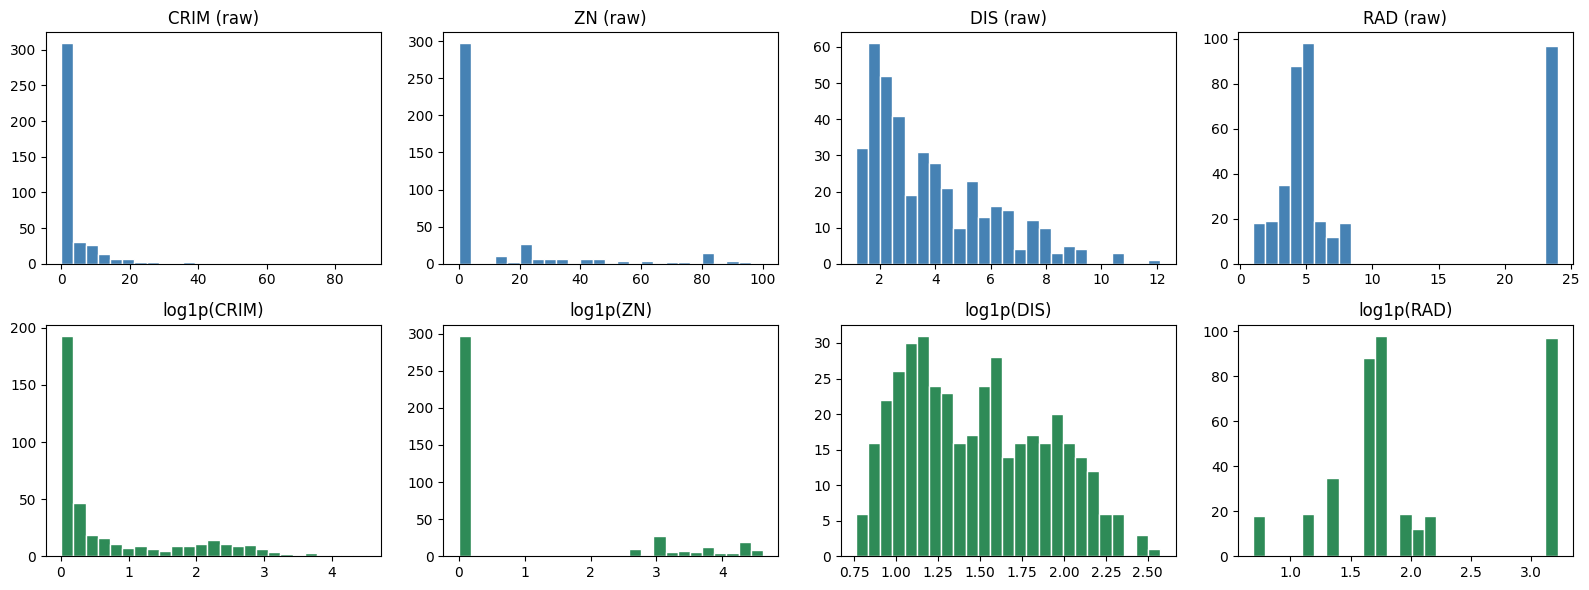

In [135]:
# Which continuous predictors are strongly right-skewed? (training split)
cont = [c for c in ALL if X_train[c].nunique() > 2]
skew_before = X_train[cont].skew()
LOG_COLS = [c for c in cont if skew_before[c] > 1.0]
skew_after = np.log1p(X_train[LOG_COLS]).skew()
display(pd.DataFrame({"skew_before": skew_before[LOG_COLS], "skew_after_log1p": skew_after}).round(2))
print("Log1p candidates:", LOG_COLS)

fig, axes = plt.subplots(2, len(LOG_COLS), figsize=(4 * len(LOG_COLS), 6), squeeze=False)
for j, c in enumerate(LOG_COLS):
    axes[0, j].hist(X_train[c], bins=25, color="steelblue", edgecolor="white"); axes[0, j].set_title(f"{c} (raw)")
    axes[1, j].hist(np.log1p(X_train[c]), bins=25, color="seagreen", edgecolor="white"); axes[1, j].set_title(f"log1p({c})")

# saving the figure
pyplot.savefig('Datasets/08_log_transforms.jpg',
               dpi = 300)
plt.tight_layout()


In [131]:
# 1) OLS significance on the training split
ols_tr = sm.OLS(y_train, sm.add_constant(X_train)).fit()
pvals = ols_tr.pvalues.drop("const")

# 2) Univariate F-test
kb = SelectKBest(f_regression, k="all").fit(X_train, y_train)

# 3) Recursive feature elimination (full ranking) on standardised features
rfe = RFE(LinearRegression(), n_features_to_select=1).fit(StandardScaler().fit_transform(X_train), y_train)

# 4) Random-forest impurity importance
rf_imp = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_train, y_train).feature_importances_

fs = pd.DataFrame({
    "OLS_p": pvals.round(4),
    "F_score": kb.scores_.round(1),
    "RFE_rank": rfe.ranking_,
    "RF_importance": rf_imp.round(4),
}, index=X_train.columns).sort_values("RFE_rank")
display(fs)

ALL = list(X_train.columns)
SEL = [c for c in ALL if pvals[c] < 0.05]
print("Dropped (OLS p >= 0.05):", [c for c in ALL if c not in SEL])
print("Selected:", SEL)

,OLS_p,F_score,RFE_rank,RF_importance
RM,0.0000,513.5,1,0.5091
LSTAT,0.0000,475.2,2,0.3092
PTRATIO,0.0000,139.7,3,0.0136
DIS,0.0000,29.0,4,0.0477
NOX,0.0002,94.6,5,0.0232
TAX,0.0022,127.6,6,0.0168
RAD,0.0001,75.7,7,0.0040
CRIM,0.0010,76.7,8,0.0442
B,0.0007,47.1,9,0.0099
ZN,0.0330,55.3,10,0.0010


Dropped (OLS p >= 0.05): ['INDUS', 'AGE']
Selected: ['CRIM', 'ZN', 'CHAS', 'NOX', 'RM', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']


**Approach.**
* Features that are not statistically significant in a multivariate OLS on the training split are dropped (`SEL`), cross-checked against the F-test, RFE ranking and forest importances in the table.
* Because tree ensembles are indifferent to a few weak features while linear/distance models can benefit, the choice between `ALL` and `SEL` is made empirically in stage 4 using cross-validation, not assumed.

# 4 Evaluate Algorithms

## a. Set aside validation dataset

In [148]:
print(f"Training rows: {len(X_train)} | Validation rows (held back until stage 6): {len(X_val)}")

kfold = KFold(n_splits=10, shuffle=True, random_state=SEED)
def cv_rmse(model, X, y):
    """10-fold CV RMSE per fold (lower is better)."""
    return -cross_val_score(model, X, y, cv=kfold, scoring="neg_root_mean_squared_error", n_jobs=-1)

def run_cv(models, X, y):
    return {n: cv_rmse(m, X, y) for n, m in models.items()}

def summarize(res):
    return pd.DataFrame({n: {"RMSE mean": s.mean(), "RMSE std": s.std()} for n, s in res.items()}).T

def boxplot(res, title, name, ax=None, order=None):
    order = order or sorted(res, key=lambda n: np.median(res[n]))
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.boxplot([res[n] for n in order])
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order, rotation=30, ha="right")
    ax.set_title(title); ax.set_ylabel("CV RMSE")


    if own: plt.tight_layout(); pyplot.savefig('Datasets/08_log_transforms.jpg')

Training rows: 404 | Validation rows (held back until stage 6): 102


The split is approximately 80% training and 20% validation.


**Why hold back the 102 validation rows?**

The validation set should remain unused during model development, including feature selection, scaling decisions, and hyperparameter tuning. This helps provide a more independent assessment of how well the final model predicts unseen housing values.

### Another Way to Set aside validation dataset

It is a good idea to use a validation hold-out set. This is a sample of the data that we hold back from our analysis and modeling. We use it right at the end of our project to confirm the accuracy of our final model. It is a smoke test that we can use to see if we messed up and to give us confidence on our estimates of accuracy on unseen data. We will use 80% of the dataset for modeling and hold back 20% for validation.

In [71]:
# Separate Data into a Training and Validation Datasets
array = df_Boston.values
X = array[:,0:13]ns
Y = array[:,13]
validation_size = 0.20
seed = 7
X_train, X_validation, Y_train, Y_validation = train_test_split(X, Y,
    test_size=validation_size, random_state=seed)

## b. Evaluate Algorithms: Baseline

In [137]:
res_base = {
    "Baseline (predict mean) — ALL": cv_rmse(DummyRegressor(strategy="mean"), X_train[ALL], y_train),
}
display(summarize(res_base).round(3))
BASE_RMSE = res_base["Baseline (predict mean) — ALL"].mean()

,RMSE mean,RMSE std
Baseline (predict mean) — ALL,9.111,1.703


## c. Spot check algorithms

In [140]:
def spot_models():
    return {
        "LR": LinearRegression(),
        "Ridge": Ridge(),
        "LASSO": Lasso(),
        "EN": ElasticNet(),
        "KNN": KNeighborsRegressor(),
        "CART": DecisionTreeRegressor(random_state=SEED),
        "SVR": SVR(),
    }

res_all = run_cv(spot_models(), X_train[ALL], y_train)
res_sel = run_cv(spot_models(), X_train[SEL], y_train)

tbl = pd.concat({"ALL features": summarize(res_all), "SELECTED features": summarize(res_sel)}, axis=1).round(3)
display(tbl)

mean_all = np.mean([s.mean() for s in res_all.values()])
mean_sel = np.mean([s.mean() for s in res_sel.values()])
FEATS = ALL if mean_all <= mean_sel else SEL
print(f"Mean CV RMSE across algorithms — ALL: {mean_all:.3f} | SELECTED: {mean_sel:.3f}  ->  using {'ALL' if FEATS is ALL else 'SELECTED'} ({len(FEATS)} features)")
LOG_IN = [c for c in LOG_COLS if c in FEATS]

ALL features          SELECTED features         
         RMSE mean RMSE std         RMSE mean RMSE std
LR           4.531    1.215             4.512    1.191
Ridge        4.529    1.238             4.521    1.205
LASSO        5.068    1.193             5.001    1.202
EN           5.150    1.182             5.097    1.202
KNN          6.176    1.289             5.883    1.287
CART         4.762    1.610             4.903    1.608
SVR          7.976    2.053             7.993    2.013

Mean CV RMSE across algorithms — ALL: 5.456 | SELECTED: 5.415  ->  using SELECTED (11 features)


We have no idea what algorithms will do well on this problem. Gut feel suggests regression algorithms like Linear Regression and ElasticNet may do well. It is also possible that decision trees and even SVM may do well. I have no idea. Let’s design our test harness. We will use 10-fold cross validation. The dataset is not too small and this is a good standard test harness configuration. We will evaluate algorithms using the Mean Squared Error (MSE) metric. MSE will give a gross idea of how wrong all predictions are (0 is perfect)

In [72]:
# Test options and evaluation metric
num_folds = 10
seed = 7
scoring = 'neg_mean_squared_error'

Let’s create a baseline of performance on this problem and spot-check a number of different algorithms. We will select a suite of different algorithms capable of working on this regression problem. The six algorithms selected include:
* Linear Algorithms: Linear Regression (LR), Lasso Regression (LASSO) and ElasticNet (EN).
* Nonlinear Algorithms: Classification and Regression Trees (CART), Support Vector Regression (SVR) and k-Nearest Neighbors (KNN).


In [73]:
# Create the List of Algorithms to Evaluate
models = []
models.append(('LR', LinearRegression()))
models.append(('LASSO', Lasso()))
models.append(('EN', ElasticNet()))
models.append(('KNN', KNeighborsRegressor()))
models.append(('CART', DecisionTreeRegressor()))
models.append(('SVR', SVR()))

The algorithms all use default tuning parameters. Let’s compare the algorithms. We will display the mean and standard deviation of MSE for each algorithm as we calculate it and collect the results for use later.

## d. Compare algorithms

In [74]:
# evaluate each model in turn
results = []
names = []
for name, model in models:
    kfold = KFold(n_splits=num_folds)
    cv_results = cross_val_score(model, X_train, Y_train, cv=kfold, scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())
    print(msg)

LR: -21.379856 (9.414264)
LASSO: -26.423561 (11.651110)
EN: -27.502259 (12.305022)
KNN: -41.896488 (13.901688)
CART: -29.748773 (14.507361)
SVR: -67.827886 (29.049138)


It looks like LR has the lowest MSE, followed closely by CART.

Let’s take a look at the distribution of scores across all cross validation folds by algorithm.

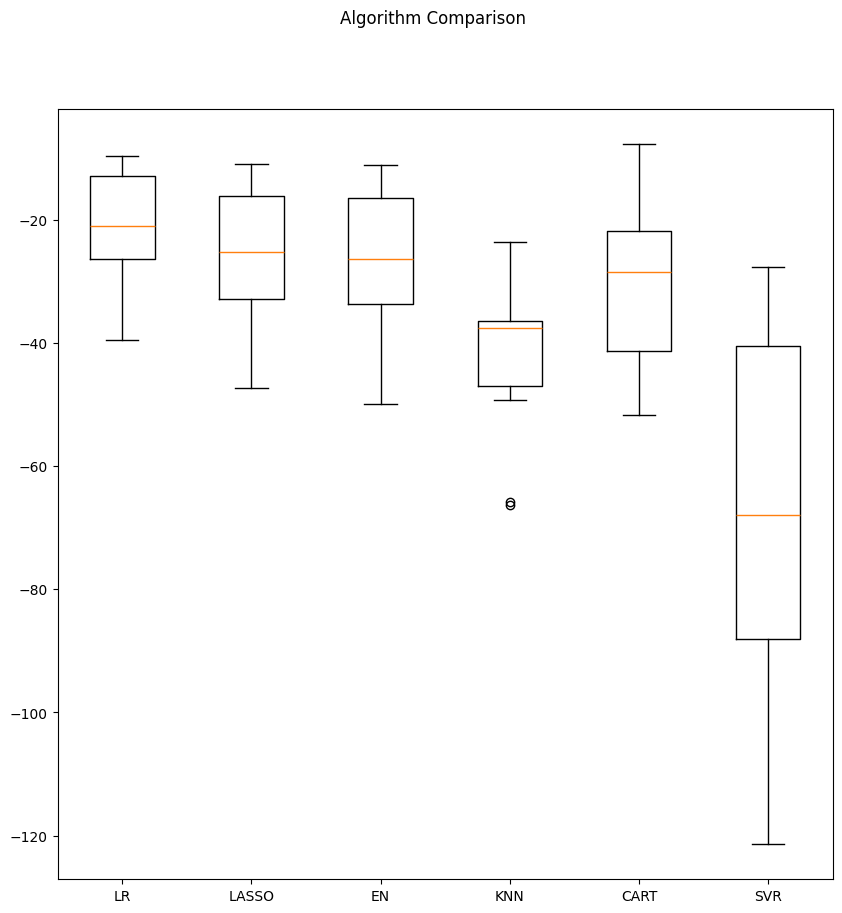

In [75]:
# Compare Algorithms
fig = pyplot.figure()
fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
pyplot.boxplot(results)
ax.set_xticklabels(names)
pyplot.show()

The differing scales of the data is probably hurting the skill of all of the algorithms and perhaps more so for SVR and KNN. In the next section we will look at running the same algorithms using a standardized copy of the data.

,RMSE mean,RMSE std
LR,4.512,1.191
Ridge,4.521,1.205
CART,4.903,1.608
LASSO,5.001,1.202
EN,5.097,1.202
KNN,5.883,1.287
SVR,7.993,2.013


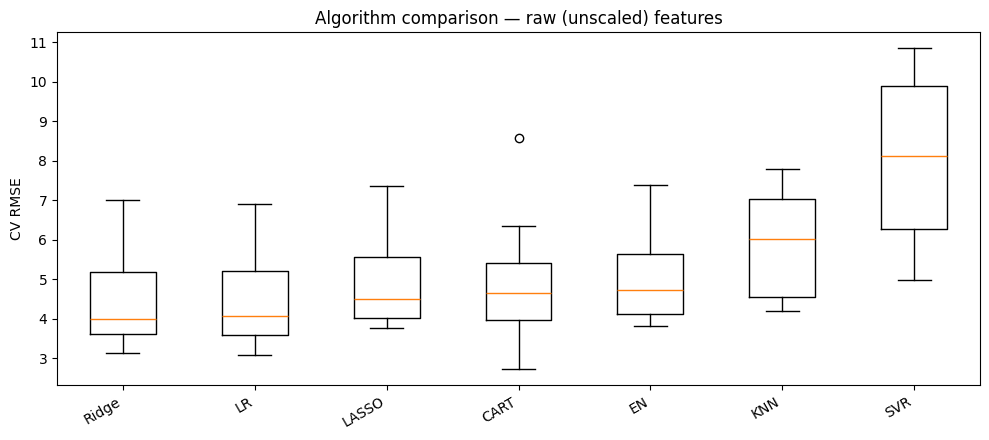

In [149]:
res_unscaled = res_all if FEATS is ALL else res_sel
boxplot(
    res_unscaled,
    "Algorithm comparison — raw (unscaled) features",
    "09_compare_unscaled")

display(
    summarize(res_unscaled).sort_values("RMSE mean").round(3))

The chart compares the seven algorithms using mean RMSE and standard deviation for raw (unscaled) features.
- Best performance: LR (Linear Regression), with a mean RMSE of `4.512`.
- Very close alternative: Ridge Regression, with a mean RMSE of `4.521`.
- Highest prediction error: SVR, with a mean RMSE of `7.993`.
- The error bars represent ±1 standard deviation across cross-validation folds.

**Interpretation:**
+ Linear Regression and Ridge Regression perform similarly and outperform the other algorithms on this dataset.
+ KNN and SVR may be sensitive to feature scales, so comparing them with scaled-feature results would be useful.

# 5 Improve Accuracy

## a. Evaluate Algorithms: Standardization

We suspect that the differing scales of the raw data may be negatively impacting the skill of some of the algorithms. Let’s evaluate the same algorithms with a standardized copy of the dataset. This is where the data is transformed such that each attribute has a mean value of zero and a standard deviation of 1. We also need to avoid data leakage when we transform the data. A good way to avoid leakage is to use pipelines that standardize the data and build the model for each fold in the cross validation test harness. That way we can get a fair estimation of how each model with standardized data might perform on unseen data.

In [76]:
# Standardize the dataset
pipelines = []
pipelines.append(('ScaledLR', Pipeline([('Scaler', StandardScaler()),('LR', LinearRegression())])))
pipelines.append(('ScaledLASSO', Pipeline([('Scaler', StandardScaler()),('LASSO', Lasso())])))
pipelines.append(('ScaledEN', Pipeline([('Scaler', StandardScaler()),('EN', ElasticNet())])))
pipelines.append(('ScaledKNN', Pipeline([('Scaler', StandardScaler()),('KNN', KNeighborsRegressor())])))
pipelines.append(('ScaledCART', Pipeline([('Scaler', StandardScaler()),('CART', DecisionTreeRegressor())])))
pipelines.append(('ScaledSVR', Pipeline([('Scaler', StandardScaler()),('SVR', SVR())])))
results = []
names = []
for name, model in pipelines:
    kfold = KFold(n_splits=num_folds)
    cv_results = cross_val_score(model, X_train, Y_train, cv=kfold, scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())
    print(msg)


ScaledLR: -21.379856 (9.414264)
ScaledLASSO: -26.607314 (8.978761)
ScaledEN: -27.932372 (10.587490)
ScaledKNN: -20.107620 (12.376949)
ScaledCART: -22.679466 (9.837127)
ScaledSVR: -29.633086 (17.009186)


Running the example provides a list of mean squared errors. We can see that scaling did have an effect on KNN, driving the error lower than the other models.

Let’s take a look at the distribution of the scores across the cross validation folds.

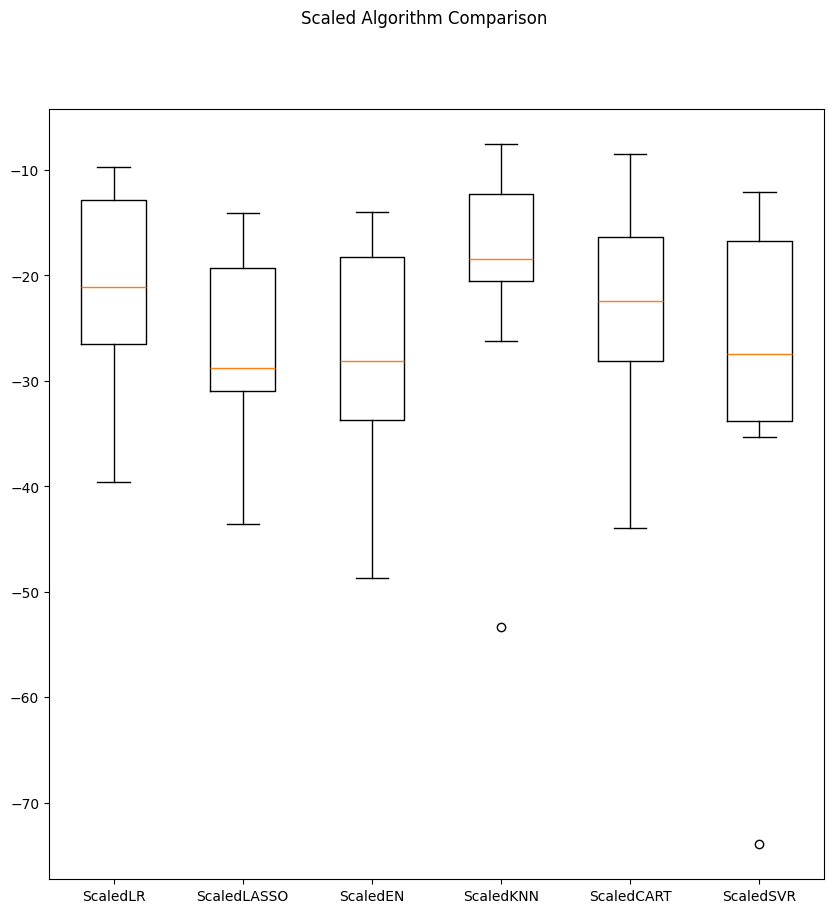

In [77]:
# Compare Algorithms
fig = pyplot.figure()
fig.suptitle('Scaled Algorithm Comparison')
ax = fig.add_subplot(111)
pyplot.boxplot(results)
ax.set_xticklabels(names)
pyplot.show()

,Raw,Standardized,Standardized + log1p
LR,4.512,4.512,4.482
Ridge,4.521,4.511,4.481
LASSO,5.001,5.102,5.096
EN,5.097,5.175,5.192
KNN,5.883,4.142,4.126
CART,4.903,4.902,4.833
SVR,7.993,5.146,4.947


Adopting log1p transform: True


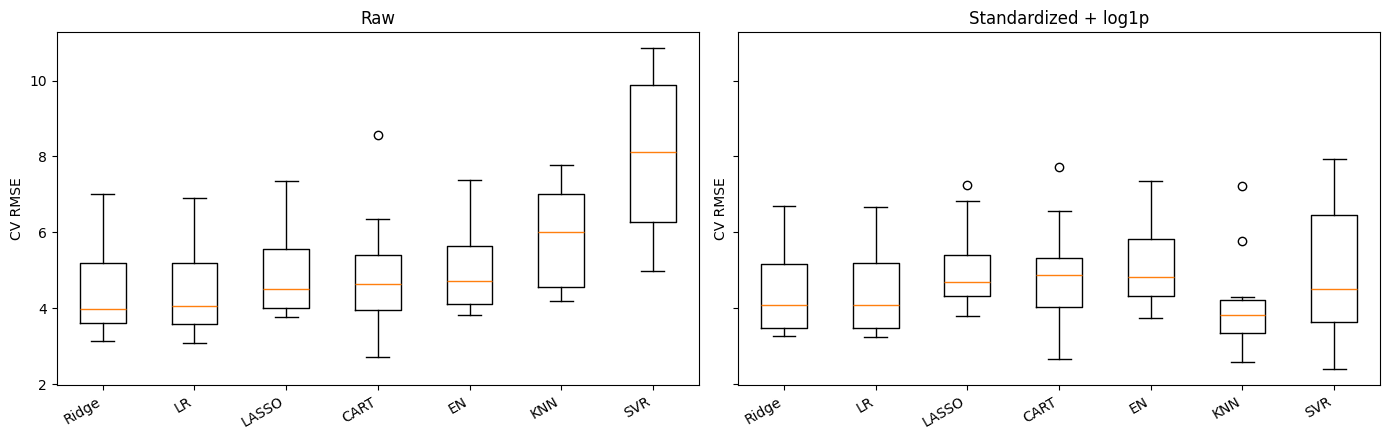

In [157]:
from sklearn.preprocessing import StandardScaler, FunctionTransformer

def build(model, feats, scale=True, log=False):
    """Preprocessing + model as one Pipeline; fitted per fold, so no leakage."""
    steps = []
    log_cols = [c for c in LOG_COLS if c in feats]
    if log and log_cols:
        steps.append(("log", ColumnTransformer([("log", FunctionTransformer(np.log1p), log_cols)], remainder="passthrough")))
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

res_scaled     = run_cv({n: build(m, FEATS, True, False) for n, m in spot_models().items()}, X_train[FEATS], y_train)
res_scaled_log = run_cv({n: build(m, FEATS, True, True)  for n, m in spot_models().items()}, X_train[FEATS], y_train)

cmp = pd.concat({
    "Raw": summarize(res_unscaled)["RMSE mean"],
    "Standardized": summarize(res_scaled)["RMSE mean"],
    "Standardized + log1p": summarize(res_scaled_log)["RMSE mean"],
}, axis=1).round(3)
display(cmp)

USE_LOG = np.mean([s.mean() for s in res_scaled_log.values()]) < np.mean([s.mean() for s in res_scaled.values()])
res_pre = res_scaled_log if USE_LOG else res_scaled
print("Adopting log1p transform:", USE_LOG)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
order = sorted(res_unscaled, key=lambda n: np.median(res_unscaled[n]))
boxplot(res_unscaled, "Raw", None, ax=ax[0], order=order)
boxplot(res_pre, "Standardized" + (" + log1p" if USE_LOG else ""), None, ax=ax[1], order=order)
plt.tight_layout(); pyplot.savefig('10_standardization_effect.jpg')

## b. Fine tune the model (grid search, 10-fold CV, training split only)

We know from the results in the previous section that KNN achieves good results on a scaled version of the dataset. But can it do better. The default value for the number of neighbors in KNN is 7. We can use a grid search to try a set of different numbers of neighbors and see if we can improve the score. The below example tries odd k values from 1 to 21, an arbitrary range covering a known good value of 7. Each *k* value (*n* neighbors) is evaluated using 10-fold cross validation on a standardized copy of the training dataset.


KNN    CV RMSE = 3.765 | best = {'n_neighbors': 5, 'weights': 'distance'}
SVR    CV RMSE = 3.112 | best = {'C': 300, 'epsilon': 1.0, 'gamma': 0.03}
Ridge  CV RMSE = 4.477 | best = {'alpha': np.float64(10.0)}


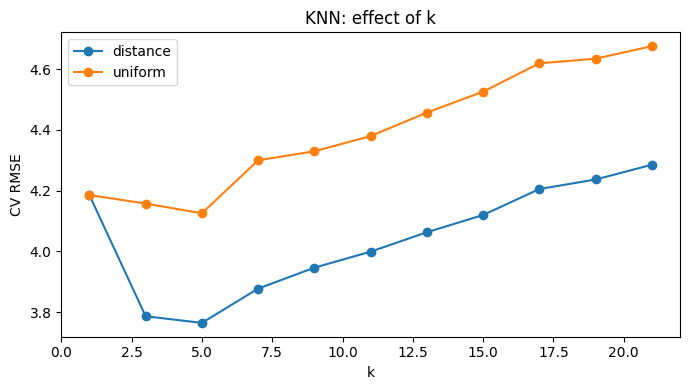

In [158]:
candidates = {}
def tune(name, model, grid):
    gs = GridSearchCV(build(model, FEATS, True, USE_LOG), grid, scoring="neg_root_mean_squared_error",
                      cv=kfold, n_jobs=-1, refit=True)
    gs.fit(X_train[FEATS], y_train)
    candidates[name] = gs
    print(f"{name:<6} CV RMSE = {-gs.best_score_:.3f} | best = { {k.split('__')[1]: v for k, v in gs.best_params_.items()} }")
    return gs

gs_knn = tune("KNN", KNeighborsRegressor(), {"model__n_neighbors": list(range(1, 22, 2)), "model__weights": ["uniform", "distance"]})
gs_svr = tune("SVR", SVR(), {"model__C": [0.1, 1, 10, 50, 100, 300], "model__gamma": ["scale", 0.01, 0.03, 0.1, 0.3], "model__epsilon": [0.1, 1.0]})
gs_rdg = tune("Ridge", Ridge(), {"model__alpha": np.logspace(-3, 3, 13)})

# KNN curve
r = pd.DataFrame(gs_knn.cv_results_)
fig, ax = plt.subplots(figsize=(7, 4))
for w, g in r.groupby("param_model__weights"):
    ax.plot(g["param_model__n_neighbors"].astype(int), -g["mean_test_score"], marker="o", label=w)
ax.set(xlabel="k", ylabel="CV RMSE", title="KNN: effect of k"); ax.legend(); plt.tight_layout(); pyplot.savefig('11_knn_tuning.jpg')

## c. Ensemble Methods

Another way that we can improve the performance of algorithms on this problem is by using ensemble methods. In this section we will evaluate four different ensemble machine learning algorithms, two boosting and two bagging methods:

* Boosting Methods: AdaBoost (AB) and Gradient Boosting(GBM).
* Bagging Methods: Random Forests (RF) and Extra Trees (ET).

We will use the same test harness as before, 10-fold cross validation and pipelines that standardize the training data for each fold.

In [80]:
# Evaluate Ensemble Algorithms on the Standardized Dataset.
ensembles = []
ensembles.append(('ScaledAB', Pipeline([('Scaler', StandardScaler()),('AB', AdaBoostRegressor())])))
ensembles.append(('ScaledGBM', Pipeline([('Scaler', StandardScaler()),('GBM', GradientBoostingRegressor())])))
ensembles.append(('ScaledRF', Pipeline([('Scaler', StandardScaler()),('RF', RandomForestRegressor())])))
ensembles.append(('ScaledET', Pipeline([('Scaler', StandardScaler()),('ET', ExtraTreesRegressor())])))
results = []
names = []
for name, model in ensembles:
    kfold = KFold(n_splits=num_folds)
    cv_results = cross_val_score(model, X_train, Y_train, cv=kfold, scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())
    print(msg)

ScaledAB: -15.709839 (7.087785)
ScaledGBM: -10.078272 (4.516956)
ScaledRF: -11.895901 (6.135087)
ScaledET: -9.099932 (5.083261)


Running the example calculates the mean squared error for each method using the default parameters. We can see that we’re generally getting better scores than our linear and nonlinear algorithms in previous sections.

We can also plot the distribution of scores across the cross validation folds.

,RMSE mean,RMSE std
ET,2.910,0.890
GBM,3.168,0.960
RF,3.372,1.149
AB,3.843,0.901


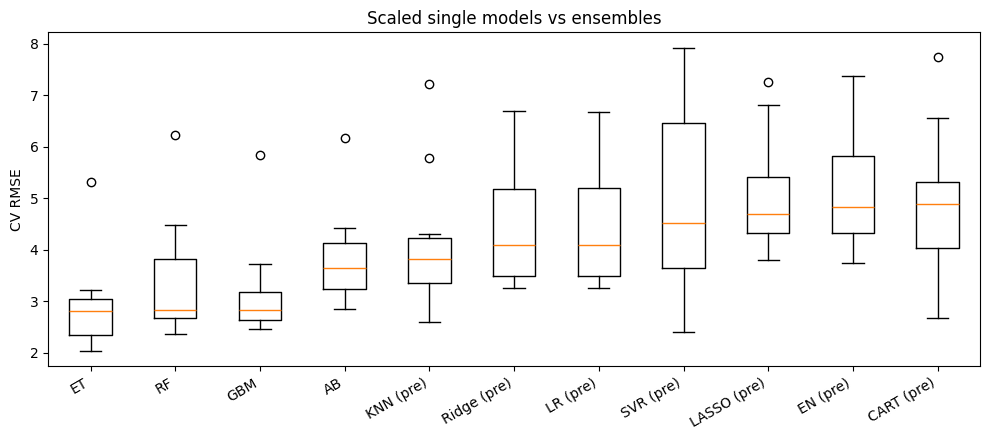

In [159]:
def ens_models():
    return {
        "AB":  AdaBoostRegressor(random_state=SEED),
        "GBM": GradientBoostingRegressor(random_state=SEED),
        "RF":  RandomForestRegressor(n_estimators=200, random_state=SEED),
        "ET":  ExtraTreesRegressor(n_estimators=200, random_state=SEED),
    }
res_ens = run_cv({n: build(m, FEATS, True, USE_LOG) for n, m in ens_models().items()}, X_train[FEATS], y_train)
display(summarize(res_ens).sort_values("RMSE mean").round(3))

combined = {**{f"{k} (pre)": v for k, v in res_pre.items()}, **res_ens}
boxplot(combined, "Scaled single models vs ensembles", "12_ensembles_vs_singles")

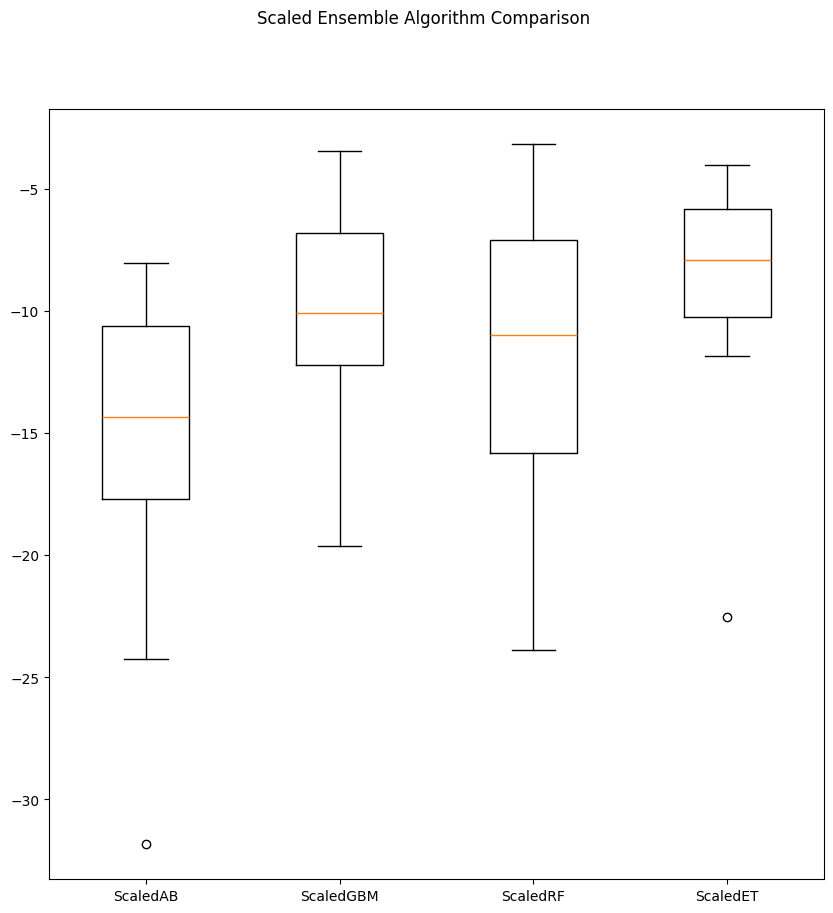

In [81]:
# Compare Algorithms
# Visualzie the Differences in Ensemble Algorithm Performance on Standardized Dataset.
fig = pyplot.figure()
fig.suptitle('Scaled Ensemble Algorithm Comparison')
ax = fig.add_subplot(111)
pyplot.boxplot(results)
ax.set_xticklabels(names)
pyplot.show()

It looks like Gradient Boosting has a better mean score, it also looks like Extra Trees has a similar distribution and perhaps a better median score.

## c. Tune Ensemble Methods

As before, we can summarize the best configuration and get an idea of how performance changed with each different configuration.

GBM    CV RMSE = 2.948 | best = {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.7}
RF     CV RMSE = 3.185 | best = {'max_features': 0.33, 'min_samples_leaf': 1}
ET     CV RMSE = 2.853 | best = {'max_features': 0.75, 'min_samples_leaf': 1}


,CV RMSE
ET,2.853
GBM,2.948
SVR,3.112
RF,3.185
KNN,3.765
Ridge,4.477


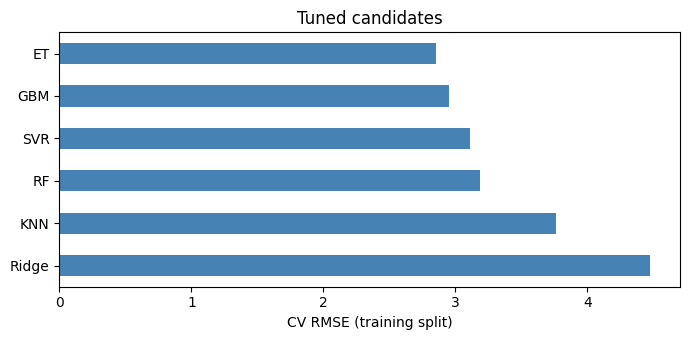

In [160]:
gs_gbm = tune("GBM", GradientBoostingRegressor(random_state=SEED), {
    "model__n_estimators": [100, 200, 400], "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 1.0]})
gs_rf = tune("RF", RandomForestRegressor(n_estimators=300, random_state=SEED), {
    "model__max_features": [0.33, 0.5, 0.75, 1.0], "model__min_samples_leaf": [1, 2, 3]})
gs_et = tune("ET", ExtraTreesRegressor(n_estimators=300, random_state=SEED), {
    "model__max_features": [0.33, 0.5, 0.75, 1.0], "model__min_samples_leaf": [1, 2, 3]})

cand = pd.DataFrame({n: {"CV RMSE": -g.best_score_} for n, g in candidates.items()}).T.sort_values("CV RMSE").round(3)
display(cand)
cand.plot(kind="barh", legend=False, figsize=(7, 3.5), color="steelblue").invert_yaxis()
plt.xlabel("CV RMSE (training split)"); plt.title("Tuned candidates"); plt.tight_layout(); pyplot.savefig("13_tuned_candidates.jpg")

*Note: the CV score of a grid search is optimistically biased (the best of many configurations was picked on those same folds). The untouched validation set in stage 6 gives the unbiased estimate.*

# 6. Finalize the Model

In this section we will finalize the gradient boosting model and evaluate it on our hold out validation dataset. First we need to prepare the model and train it on the entire training dataset. This includes standardizing the training dataset before training.

## a. Predictions on validation dataset

We can then scale the inputs for the validation dataset and generate predictions.

Selected on CV (training split only): ET


,RMSE,MAE,R2
Baseline (mean),8.989,6.219,-0.000
Linear regression (scaled),5.676,3.831,0.601
FINAL: tuned ET,3.559,2.205,0.843


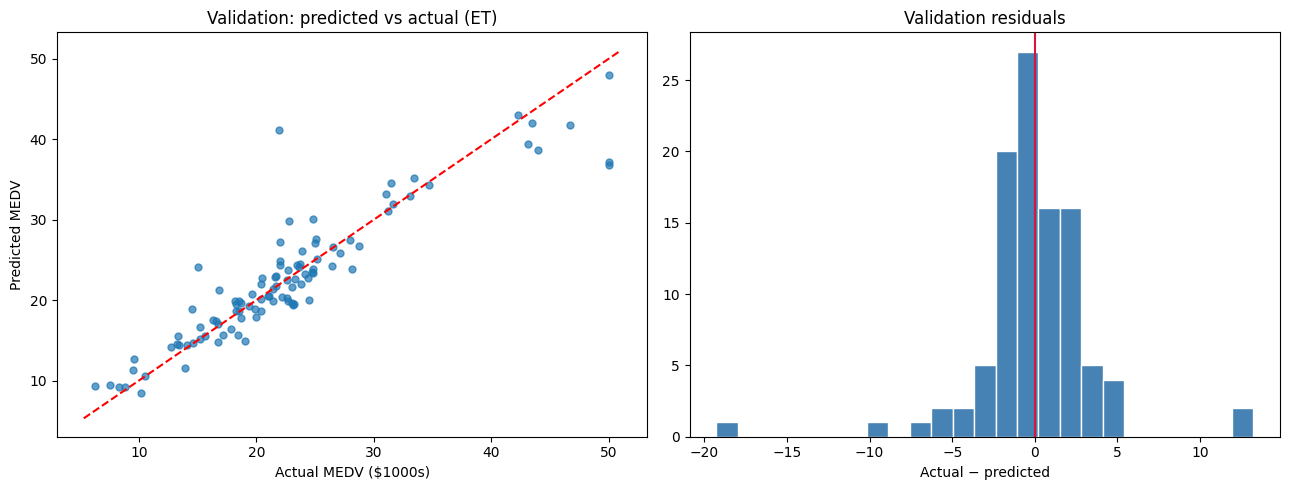

In [164]:


best_name = min(candidates, key=lambda n: -candidates[n].best_score_)
print("Selected on CV (training split only):", best_name)

final_model = clone(candidates[best_name].best_estimator_)
final_model.fit(X_train[FEATS], y_train)
pred = final_model.predict(X_val[FEATS])

def metrics(y_true, y_pred):
    return {"RMSE": mean_squared_error(y_true, y_pred) ** 0.5, "MAE": mean_absolute_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}

refs = {
    "Baseline (mean)": DummyRegressor().fit(X_train[ALL], y_train).predict(X_val[ALL]),
    "Linear regression (scaled)": build(LinearRegression(), FEATS, True, USE_LOG).fit(X_train[FEATS], y_train).predict(X_val[FEATS]),
    f"FINAL: tuned {best_name}": pred,
}
val_tbl = pd.DataFrame({k: metrics(y_val, v) for k, v in refs.items()}).T.round(3)
display(val_tbl)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_val, pred, s=25, alpha=.7); lim = [min(y_val.min(), pred.min()) - 1, max(y_val.max(), pred.max()) + 1]
ax[0].plot(lim, lim, "r--"); ax[0].set(xlabel="Actual MEDV ($1000s)", ylabel="Predicted MEDV", title=f"Validation: predicted vs actual ({best_name})")
res_v = y_val - pred
ax[1].hist(res_v, bins=25, color="steelblue", edgecolor="white"); ax[1].axvline(0, color="crimson")
ax[1].set(title="Validation residuals", xlabel="Actual − predicted")

plt.tight_layout(); pyplot.savefig("14_validation_performance.jpg")

## b. Create standalone model on entire training dataset

In [168]:
# The final pipeline (log1p -> StandardScaler -> estimator) is refit on the ENTIRE training split with tuned hyper-parameters.
standalone = clone(candidates[best_name].best_estimator_).fit(X_train[FEATS], y_train)
print(standalone)
print("Identical to the model evaluated above:", np.allclose(standalone.predict(X_val[FEATS]), pred))

Pipeline(steps=[('log',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('log',
                                                  FunctionTransformer(func=<ufunc 'log1p'>),
                                                  ['CRIM', 'ZN', 'DIS',
                                                   'RAD'])])),
                ('scale', StandardScaler()),
                ('model',
                 ExtraTreesRegressor(max_features=0.75, n_estimators=300,
                                     random_state=7))])
Identical to the model evaluated above: True


## c. Save model for later use

In [173]:
MODEL_PATH = Path("boston_model.joblib")
joblib.dump(standalone, MODEL_PATH)

v = metrics(y_val, pred)
card = {
    "created": datetime.now().isoformat(timespec="seconds"),
    "algorithm": best_name,
    "best_params": {k.split("__", 1)[1]: (v_ if isinstance(v_, (int, float, str)) else float(v_)) for k, v_ in candidates[best_name].best_params_.items()},
    "features_in_order": FEATS,
    "log1p_columns": [c for c in LOG_COLS if c in FEATS] if USE_LOG else [],
    "standardised": True,
    "target": "MEDV (USD 1000s, 1970 values)",
    "validation": {k: round(float(x), 4) for k, x in v.items()},
    "cv_rmse_training": round(float(-candidates[best_name].best_score_), 4),
    "random_seed": SEED,
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
    "caveat": "Trained on 1970 Boston-area tract data; includes the ethically problematic feature B. Benchmark use only.",
}
Path("boston_model_card.json").write_text(json.dumps(card, indent=2))

# Reload test: what a future script / service would do
loaded = joblib.load(MODEL_PATH)
assert np.allclose(loaded.predict(X_val[FEATS]), pred)
print("Saved:", MODEL_PATH, f"({MODEL_PATH.stat().st_size/1024:.0f} KB) + boston_model_card.json  | reload check passed")

new_tract = pd.DataFrame([{"CRIM": 0.1, "ZN": 12.5, "INDUS": 7.0, "CHAS": 0, "NOX": 0.5, "RM": 6.4, "AGE": 60.0,
                           "DIS": 4.0, "RAD": 5, "TAX": 300, "PTRATIO": 17.0, "B": 390.0, "LSTAT": 10.0}])[FEATS]
print(f"Example prediction for a new tract: ${loaded.predict(new_tract)[0]*1000:,.0f}")
print(json.dumps(card["validation"]))

Saved: boston_model.joblib (16745 KB) + boston_model_card.json  | reload check passed
Example prediction for a new tract: $22,990
{"RMSE": 3.5587, "MAE": 2.2055, "R2": 0.8433}


### Using the saved model elsewhere

```
import joblib, pandas as pd
model = joblib.load("boston_model.joblib")          # needs the same scikit-learn major/minor version
X_new = pd.DataFrame([...])[features_in_order]      # column list is in boston_model_card.json
model.predict(X_new)                                # MEDV in $1000s
```

The pipeline already contains the log1p and scaling steps, so pass raw feature values.